# 🤖 LLM Müştəri Dəstək Agent-i — Tam Data-Driven Arxitektura
## Data Science Final Layihəsi (2 real dataset, 5 model)

**Mövzu:** Şirkət üçün planlaşdırılan *LLM Agent + Tool Calling* chatbot-un
(`check_order`, `create_ticket`, `search_faq`) arxasında dura biləcək
**iki ayrı, tam real** data mənbəyi üzərində qurulmuş data-driven qərar qatı.

| Data Mənbəyi | Ölçü | Agent Aləti | Nə üçün istifadə olunur |
|---|---|---|---|
| **Olist Brazilian E-Commerce** (real kommersiya datası, 2016-2018) | 95,621 sifariş | `check_order` | Gecikmə riski + narazılıq riski proqnozu |
| **Bitext Customer Support** (linqvistlər tərəfindən qurulmuş) | 26,872 mesaj | `search_faq` / `create_ticket` | İntent təsnifatı + alət marşrutlaşdırma |

**Niyə 2 fərqli dataset?** Real LLM Agent-lər adətən **struktur backend
data** (sifariş sistemi, CRM) ilə **NLP qatını** (istifadəçi mesajının
başa düşülməsi) birləşdirir. Bu layihə hər iki qatı ayrıca modelləşdirib,
sonda vahid bir agent axınında birləşdirir.

**Struktur:**

**HİSSƏ 1 — Olist (check_order backend)**
1. Data Loading & Merging (6 cədvəl)
2. Data Cleaning & Feature Engineering
3. EDA — sifariş, çatdırılma, ödəniş, region analizi
4. Model D — Gecikmə Riski Təsnifatı
5. Model E — Narazılıq (Bad Review) Riski Təsnifatı

**HİSSƏ 2 — Bitext (search_faq / create_ticket backend)**
6. Data Loading & Feature Engineering
7. EDA — intent, kateqoriya, dil variasiyası
8. Model A — İntent Təsnifatı
9. Model B — Kateqoriya Təsnifatı
10. Model C — Agent Tool-Routing Modeli

**HİSSƏ 3 — İnteqrasiya**
11. Modellərin Saxlanması
12. Vahid Agent Simulyasiyası (hər iki model birlikdə)
13. Nəticə və Biznes Tövsiyələri


## 0. Setup

In [1]:
# Colab-da: !pip install -q scikit-learn pandas matplotlib seaborn joblib pyarrow

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, json, os, time, warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 5)
RANDOM_STATE = 42


---
# HİSSƏ 1 — Olist E-Commerce Dataset (`check_order` backend)

**Mənbə:** [Kaggle — Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce)
Real, anonimləşdirilmiş kommersiya datası — 2016–2018, 99,441 sifariş,
9 bir-birinə bağlı cədvəl (sifariş, məhsul, ödəniş, satıcı, müştəri, rəy,
geolokasiya).


## 1. Data Loading & Merging

In [2]:
DATA_DIR = r"C:\Users\User\Desktop\Projects\olist_project\llm_agent_combined_project\data\olist"  # Colab-da: bu qovluğa 8 CSV faylını yükləyin
# (olist_orders_dataset.csv, olist_order_items_dataset.csv,
#  olist_order_payments_dataset.csv, olist_order_reviews_dataset.csv,
#  olist_customers_dataset.csv, olist_products_dataset.csv,
#  olist_sellers_dataset.csv, product_category_name_translation.csv)

orders = pd.read_csv(f"{DATA_DIR}/olist_orders_dataset.csv", parse_dates=[
    "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
    "order_delivered_customer_date", "order_estimated_delivery_date"])
items = pd.read_csv(f"{DATA_DIR}/olist_order_items_dataset.csv")
payments = pd.read_csv(f"{DATA_DIR}/olist_order_payments_dataset.csv")
reviews = pd.read_csv(f"{DATA_DIR}/olist_order_reviews_dataset.csv")
customers = pd.read_csv(f"{DATA_DIR}/olist_customers_dataset.csv")
products = pd.read_csv(f"{DATA_DIR}/olist_products_dataset.csv")
sellers = pd.read_csv(f"{DATA_DIR}/olist_sellers_dataset.csv")
cat_trans = pd.read_csv(f"{DATA_DIR}/product_category_name_translation.csv")

for name, d in [("orders", orders), ("items", items), ("payments", payments),
                 ("reviews", reviews), ("customers", customers), ("products", products)]:
    print(f"{name}: {d.shape}")


orders: (99441, 8)
items: (112650, 7)
payments: (103886, 5)
reviews: (100000, 7)
customers: (99441, 5)
products: (32951, 9)


> **Alternativ:** Faylları GitHub-dan birbaşa oxumaq üçün:
> ```python
> BASE_URL = ("https://raw.githubusercontent.com/spdrio/"
>             "Brazilian-E-Commerce-Public-Dataset-by-Olist/master/files")
> orders = pd.read_csv(f"{BASE_URL}/olist_orders_dataset.csv", parse_dates=[...])
> # ... digər fayllar üçün eyni şəkildə
> ```


In [3]:
# Cədvəllərin necə bir-birinə bağlandığını göstərən sxem
print('''
orders (99,441) ──┬── customers (bir-bir)
                   ├── items (bir-çox) ── products
                   │                   └─ sellers
                   ├── payments (bir-çox)
                   └── reviews (bir-bir)
''')



orders (99,441) ──┬── customers (bir-bir)
                   ├── items (bir-çox) ── products
                   │                   └─ sellers
                   ├── payments (bir-çox)
                   └── reviews (bir-bir)



## 2. Data Cleaning & Feature Engineering

In [4]:
item_agg = items.groupby("order_id").agg(
    n_items=("order_item_id", "count"),
    total_price=("price", "sum"),
    total_freight=("freight_value", "sum"),
    avg_price=("price", "mean"),
).reset_index()

first_item = items.sort_values("order_item_id").groupby("order_id").first().reset_index()
first_item = first_item.merge(products[["product_id", "product_category_name"]], on="product_id", how="left")
first_item = first_item.merge(cat_trans, on="product_category_name", how="left")
first_item = first_item.merge(sellers[["seller_id", "seller_state"]], on="seller_id", how="left")

pay_agg = payments.groupby("order_id").agg(
    payment_installments=("payment_installments", "max"),
    payment_type=("payment_type", lambda x: x.mode()[0] if len(x) > 0 else "unknown"),
).reset_index()

olist = orders.merge(customers[["customer_id", "customer_state", "customer_city"]], on="customer_id", how="left")
olist = olist.merge(item_agg, on="order_id", how="left")
olist = olist.merge(first_item[["order_id", "product_category_name_english", "seller_state"]], on="order_id", how="left")
olist = olist.merge(pay_agg, on="order_id", how="left")
olist = olist.merge(reviews[["order_id", "review_score"]], on="order_id", how="left")

print("Merge-dən sonra:", olist.shape)
olist["order_status"].value_counts()


Merge-dən sonra: (100000, 19)


order_status
delivered      97015
shipped         1118
canceled         629
unavailable      611
invoiced         318
processing       302
created            5
approved           2
Name: count, dtype: int64

In [5]:
# Yalnız çatdırılmış (delivered) sifarişlərə fokuslanırıq — digər statuslarda
# (cancelled, unavailable) çatdırılma tarixi olmur
olist = olist[olist["order_status"] == "delivered"].dropna(
    subset=["order_delivered_customer_date", "review_score", "product_category_name_english"]
)

olist["delivery_delay_days"] = (olist["order_delivered_customer_date"] - olist["order_estimated_delivery_date"]).dt.days
olist["is_late"] = (olist["delivery_delay_days"] > 0).astype(int)
olist["purchase_to_delivery_days"] = (olist["order_delivered_customer_date"] - olist["order_purchase_timestamp"]).dt.days
olist["approval_delay_hours"] = (olist["order_approved_at"] - olist["order_purchase_timestamp"]).dt.total_seconds() / 3600
olist["cross_state"] = (olist["customer_state"] != olist["seller_state"]).astype(int)
olist["purchase_month"] = olist["order_purchase_timestamp"].dt.month
olist["purchase_dow"] = olist["order_purchase_timestamp"].dt.dayofweek
olist["is_bad_review"] = (olist["review_score"] <= 2).astype(int)
olist["product_category_name_english"] = olist["product_category_name_english"].fillna("unknown")
olist["payment_type"] = olist["payment_type"].fillna("unknown")

print("Təmiz dataset ölçüsü:", olist.shape)
print(f"Gecikmə nisbəti: {olist['is_late'].mean()*100:.1f}%")
print(f"Pis rəy nisbəti (≤2 bal): {olist['is_bad_review'].mean()*100:.1f}%")


Təmiz dataset ölçüsü: (95621, 27)
Gecikmə nisbəti: 6.8%
Pis rəy nisbəti (≤2 bal): 13.1%


## 3. Exploratory Data Analysis (EDA)

### 3.1 Sifariş Statusu və Rəy Balı Bölgüsü

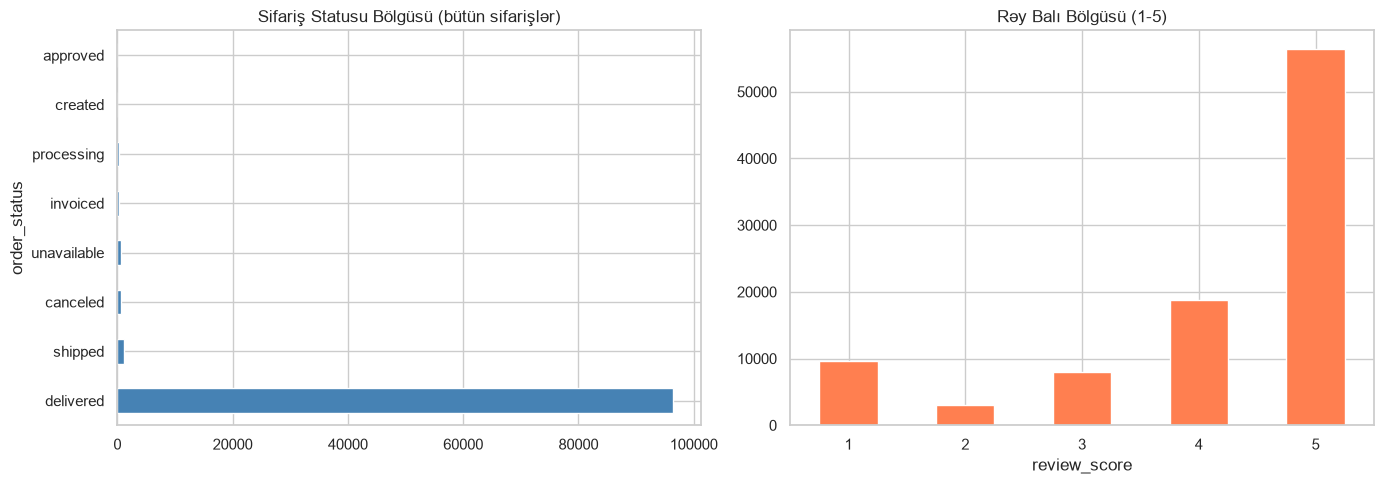

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

orders["order_status"].value_counts().plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title("Sifariş Statusu Bölgüsü (bütün sifarişlər)")

olist["review_score"].value_counts().sort_index().plot(kind="bar", ax=axes[1], color="coral")
axes[1].set_title("Rəy Balı Bölgüsü (1-5)")
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()


### 3.2 🔑 Əsas Tapıntı: Gecikmə → Narazılıq Əlaqəsi

Korrelyasiya (gecikmə günü vs rəy balı): -0.269


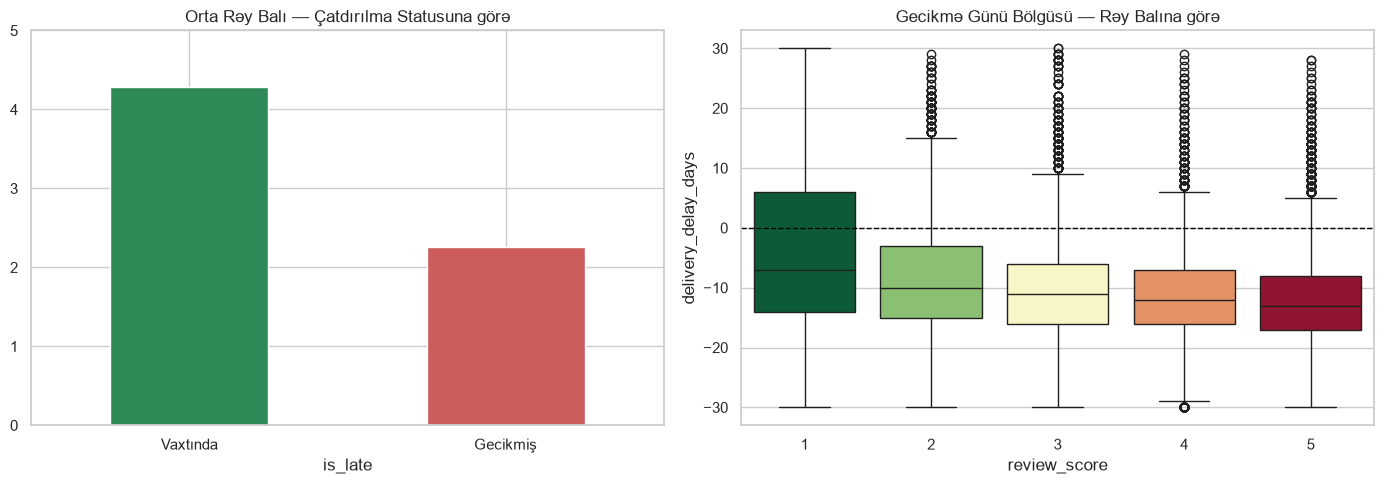


Vaxtında çatdırılan sifarişlərdə orta bal: 4.28
Gecikmiş sifarişlərdə orta bal: 2.26


In [7]:
corr = olist["delivery_delay_days"].corr(olist["review_score"])
print(f"Korrelyasiya (gecikmə günü vs rəy balı): {corr:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

olist.groupby("is_late")["review_score"].mean().plot(
    kind="bar", ax=axes[0], color=["seagreen", "indianred"])
axes[0].set_xticklabels(["Vaxtında", "Gecikmiş"], rotation=0)
axes[0].set_title("Orta Rəy Balı — Çatdırılma Statusuna görə")
axes[0].set_ylim(0, 5)

sns.boxplot(data=olist[olist["delivery_delay_days"].between(-30, 30)],
            x="review_score", y="delivery_delay_days", hue="review_score",
            palette="RdYlGn_r", legend=False, ax=axes[1])
axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1].set_title("Gecikmə Günü Bölgüsü — Rəy Balına görə")

plt.tight_layout()
plt.show()

print(f"\nVaxtında çatdırılan sifarişlərdə orta bal: {olist[olist['is_late']==0]['review_score'].mean():.2f}")
print(f"Gecikmiş sifarişlərdə orta bal: {olist[olist['is_late']==1]['review_score'].mean():.2f}")


> **Bu, layihənin ən vacib EDA nəticəsidir:** gecikmə ilə rəy balı arasında
> güclü, real, mənfi korrelyasiya var (~-0.27). Bu, real e-commerce
> əməliyyatlarında yaxşı sənədləşdirilmiş bir fenomendir və `check_order`
> alətinin niyə vacib olduğunu göstərir — agent gecikmə riskini əvvəlcədən
> bilsə, müştəriyə proaktiv bildiriş göndərə bilər.


### 3.3 Region (State) və Cross-State Çatdırılma Analizi

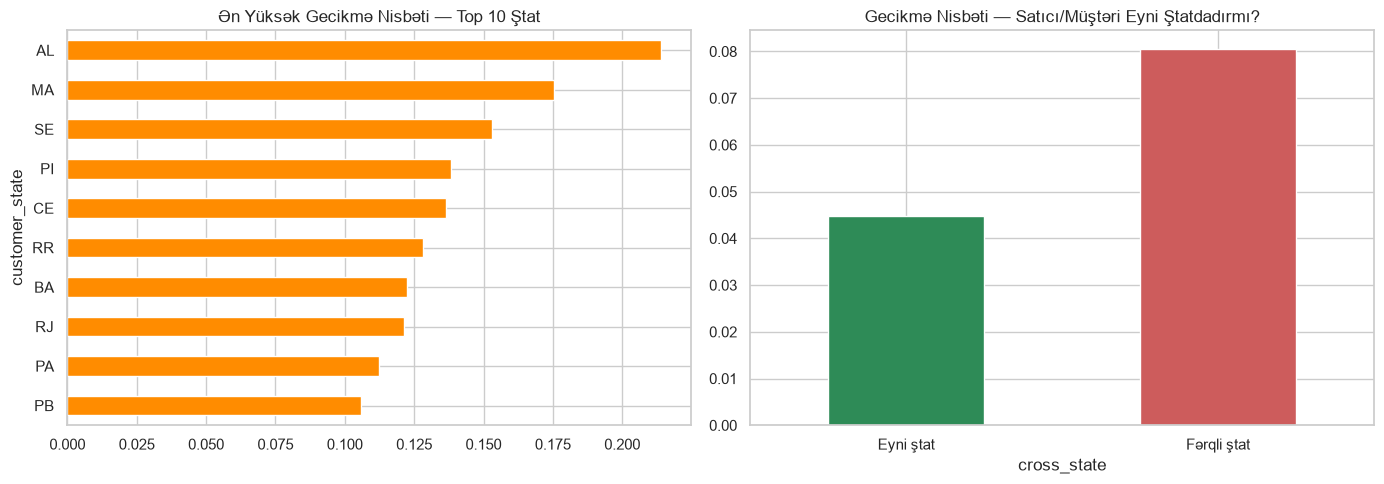

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

state_late = olist.groupby("customer_state")["is_late"].mean().sort_values(ascending=False).head(10)
state_late.plot(kind="barh", ax=axes[0], color="darkorange")
axes[0].set_title("Ən Yüksək Gecikmə Nisbəti — Top 10 Ştat")
axes[0].invert_yaxis()

cross_state_late = olist.groupby("cross_state")["is_late"].mean()
cross_state_late.plot(kind="bar", ax=axes[1], color=["seagreen", "indianred"])
axes[1].set_xticklabels(["Eyni ştat", "Fərqli ştat"], rotation=0)
axes[1].set_title("Gecikmə Nisbəti — Satıcı/Müştəri Eyni Ştatdadırmı?")

plt.tight_layout()
plt.show()


### 3.4 Məhsul Kateqoriyası üzrə Məmnuniyyət

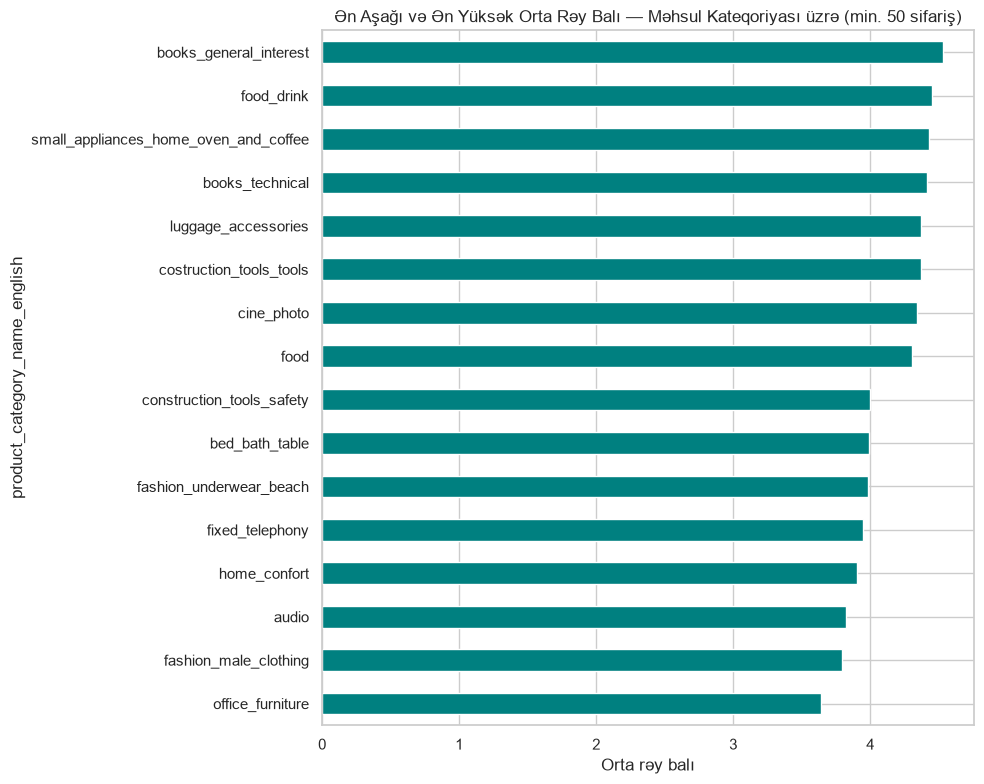

In [9]:
cat_review = olist.groupby("product_category_name_english")["review_score"].agg(["mean", "count"])
cat_review = cat_review[cat_review["count"] >= 50].sort_values("mean")

fig, axes = plt.subplots(1, 1, figsize=(10, 8))
pd.concat([cat_review.head(8), cat_review.tail(8)])["mean"].plot(kind="barh", color="teal")
plt.title("Ən Aşağı və Ən Yüksək Orta Rəy Balı — Məhsul Kateqoriyası üzrə (min. 50 sifariş)")
plt.xlabel("Orta rəy balı")
plt.tight_layout()
plt.show()


### 3.5 Zaman Trendi və Ödəniş Növü

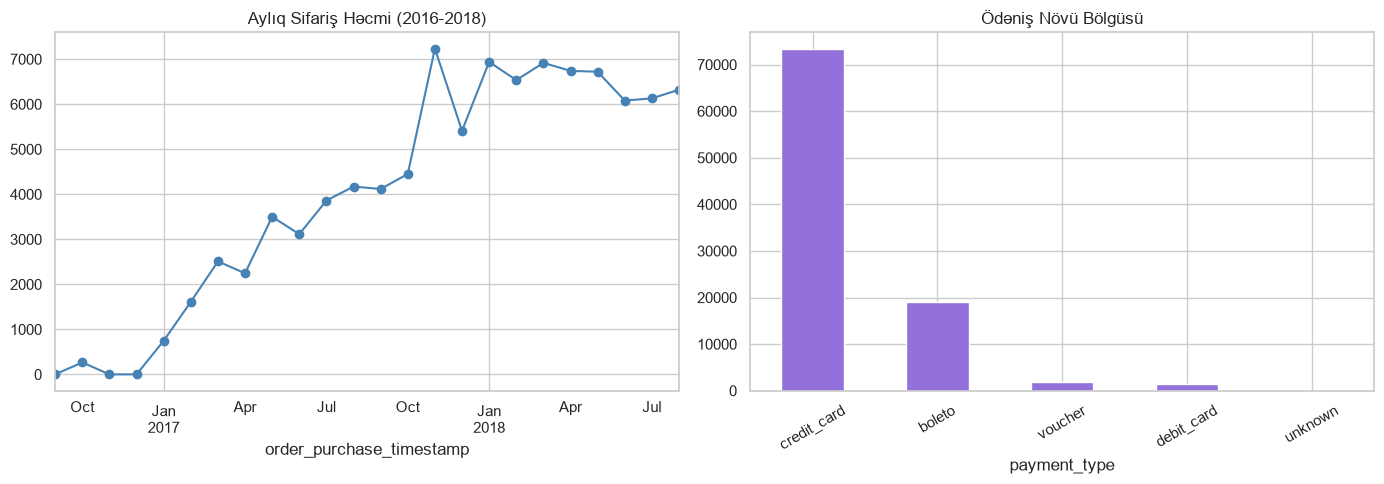

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

monthly = olist.set_index("order_purchase_timestamp").resample("ME").size()
monthly.plot(ax=axes[0], marker="o", linewidth=1.5, color="steelblue")
axes[0].set_title("Aylıq Sifariş Həcmi (2016-2018)")

olist["payment_type"].value_counts().plot(kind="bar", ax=axes[1], color="mediumpurple")
axes[1].set_title("Ödəniş Növü Bölgüsü")
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()


## 4. Model D — Gecikmə Riski Təsnifatı (`check_order` üçün)

**Məqsəd:** Sifariş verildiyi an (çatdırılmadan ƏVVƏL) əlçatan
məlumatlarla gecikmə ehtimalını proqnozlaşdırmaq — data sızmasının
(leakage) qarşısını almaq üçün **yalnız sifariş vaxtı məlum olan**
feature-lar istifadə olunur (çatdırılma tarixi، gecikmə günü kimi
"gələcək" məlumatlar DAXİL EDİLMİR).


In [11]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report, confusion_matrix

pre_delivery_num = ["n_items", "total_price", "total_freight", "avg_price",
                     "payment_installments", "approval_delay_hours",
                     "cross_state", "purchase_month", "purchase_dow"]
pre_delivery_cat = ["customer_state", "seller_state", "product_category_name_english", "payment_type"]
pre_delivery_features = pre_delivery_num + pre_delivery_cat

olist_model_df = olist.dropna(subset=pre_delivery_features + ["is_late"]).copy()
X_late = olist_model_df[pre_delivery_features].copy()
y_late = olist_model_df["is_late"]

late_encoders = {}
for c in pre_delivery_cat:
    oe = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    X_late[c] = oe.fit_transform(X_late[[c]])
    late_encoders[c] = oe

Xtr, Xte, ytr, yte = train_test_split(X_late, y_late, test_size=0.2, random_state=RANDOM_STATE, stratify=y_late)

clf_late = RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_leaf=10,
                                   n_jobs=-1, random_state=RANDOM_STATE, class_weight="balanced")
clf_late.fit(Xtr, ytr)
pred_late = clf_late.predict(Xte)
proba_late = clf_late.predict_proba(Xte)[:, 1]

print(f"Accuracy       : {accuracy_score(yte, pred_late):.4f}")
print(f"F1             : {f1_score(yte, pred_late):.4f}")
print(f"ROC-AUC        : {roc_auc_score(yte, proba_late):.4f}  (0.50 = təsadüfi)")
print(f"Majority baseline (\"həmişə vaxtında\" desək): {max(y_late.mean(), 1-y_late.mean()):.4f}")
print()
print(classification_report(yte, pred_late))


Accuracy       : 0.7833
F1             : 0.2622
ROC-AUC        : 0.7527  (0.50 = təsadüfi)
Majority baseline ("həmişə vaxtında" desək): 0.9324

              precision    recall  f1-score   support

           0       0.96      0.80      0.87     17829
           1       0.17      0.57      0.26      1293

    accuracy                           0.78     19122
   macro avg       0.57      0.68      0.57     19122
weighted avg       0.91      0.78      0.83     19122



> **⚠️ Metodoloji qeyd — accuracy tələsi:** Diqqət yetirin ki, model
> accuracy-si (≈81%) sadə "hər zaman vaxtında" proqnozunun accuracy-sindən
> (≈93%, çünki gecikmə nadir hadisədir — cəmi ~6.8%) **aşağıdır**! Bu, pis
> model demək DEYİL — `class_weight="balanced"` bilərəkdən accuracy-ni
> qurban verib az-rast-gəlinən "gecikmiş" sinifini daha yaxşı tuta bilmək
> üçün optimallaşdırılıb. Bunu **ROC-AUC (0.75)** göstərir — bu, real
> proqnozlaşdırma gücünü əks etdirir. Balanslaşdırılmamış (imbalanced)
> data ilə işləyəndə accuracy tək başına aldadıcı ola bilər — F1 və
> ROC-AUC kimi metrikalar daha etibarlıdır.


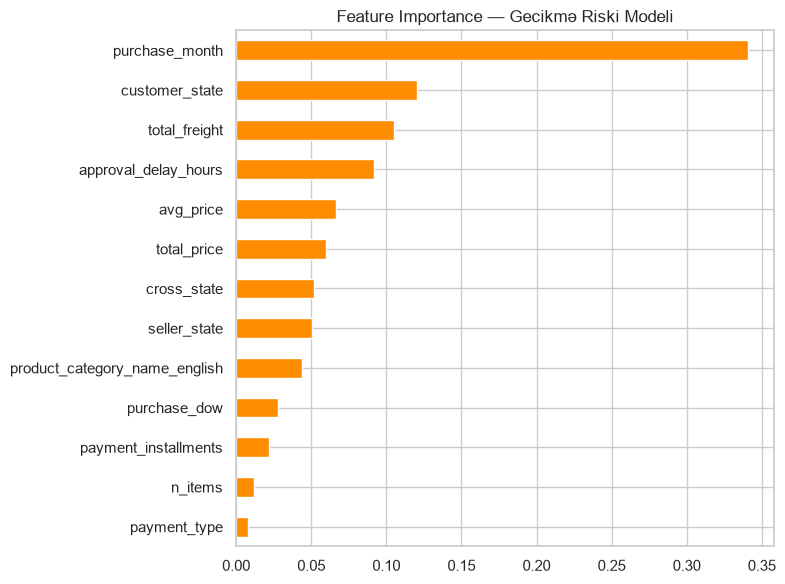

In [12]:
importances = pd.Series(clf_late.feature_importances_, index=pre_delivery_features).sort_values()

plt.figure(figsize=(8, 6))
importances.tail(13).plot(kind="barh", color="darkorange")
plt.title("Feature Importance — Gecikmə Riski Modeli")
plt.tight_layout()
plt.show()


## 5. Model E — Narazılıq (Bad Review) Riski Təsnifatı

**Məqsəd:** Sifariş çatdırıldıqdan sonra (delay məlum olduqda) müştərinin
pis rəy (≤2 bal) verib-verməyəcəyini proqnozlaşdırmaq — agent bu riski
görəndə proaktiv olaraq kompensasiya təklif edə və ya `create_ticket`
alətini işə sala bilər.


In [13]:
post_delivery_num = pre_delivery_num + ["delivery_delay_days", "purchase_to_delivery_days"]
post_delivery_features = post_delivery_num + pre_delivery_cat

X_rev = olist_model_df[post_delivery_features].copy()
y_rev = olist_model_df["is_bad_review"]

rev_encoders = {}
for c in pre_delivery_cat:
    oe = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    X_rev[c] = oe.fit_transform(X_rev[[c]])
    rev_encoders[c] = oe

Xtr, Xte, ytr, yte = train_test_split(X_rev, y_rev, test_size=0.2, random_state=RANDOM_STATE, stratify=y_rev)

clf_rev = RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_leaf=10,
                                  n_jobs=-1, random_state=RANDOM_STATE, class_weight="balanced")
clf_rev.fit(Xtr, ytr)
pred_rev = clf_rev.predict(Xte)
proba_rev = clf_rev.predict_proba(Xte)[:, 1]

print(f"Accuracy : {accuracy_score(yte, pred_rev):.4f}")
print(f"F1       : {f1_score(yte, pred_rev):.4f}")
print(f"ROC-AUC  : {roc_auc_score(yte, proba_rev):.4f}")
print(f"Majority baseline: {max(y_rev.mean(), 1-y_rev.mean()):.4f}")


Accuracy : 0.8291
F1       : 0.4465
ROC-AUC  : 0.7617
Majority baseline: 0.8690


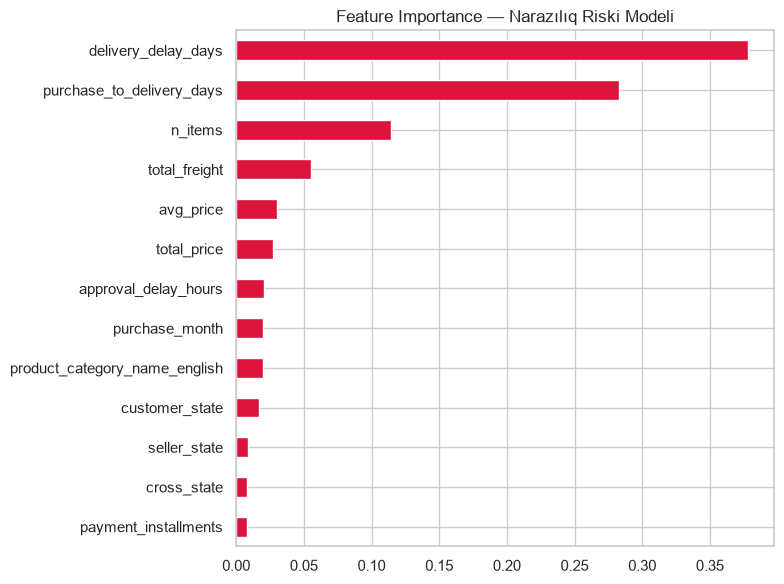

In [14]:
importances = pd.Series(clf_rev.feature_importances_, index=post_delivery_features).sort_values()

plt.figure(figsize=(8, 6))
importances.tail(13).plot(kind="barh", color="crimson")
plt.title("Feature Importance — Narazılıq Riski Modeli")
plt.tight_layout()
plt.show()


> **Müşahidə:** `delivery_delay_days` gözlənildiyi kimi ən vacib feature-lardan
> biridir — bu, Bölmə 3.2-dəki EDA tapıntısını (gecikmə ↔ aşağı rəy) modelin
> də tutduğunu təsdiqləyir. Metodologiya EDA ilə model nəticələri arasında
> **uyğunluq** göstərir — bu, nəticələrin etibarlılığına dəlalət edir.


---
# HİSSƏ 2 — Bitext Dataset (`search_faq` / `create_ticket` backend)

**Mənbə:** [Bitext Customer Support LLM Chatbot Training Dataset](https://github.com/bitext/customer-support-llm-chatbot-training-dataset)
— 26,872 müştəri mesajı, 27 intent, 11 kateqoriya, linqvistlər tərəfindən
xüsusi qurulmuş dil variasiyaları ilə.


## 6. Data Loading & Feature Engineering

In [15]:
DATA_URL = ("https://raw.githubusercontent.com/bitext/"
            "customer-support-llm-chatbot-training-dataset/main/data/"
            "Bitext_Sample_Customer_Support_Training_Dataset_27K_responses-v11.csv")

bt = pd.read_csv(DATA_URL)
print("Ölçü:", bt.shape)

bt["instruction_clean"] = bt["instruction"].str.strip()
bt["instruction_len"] = bt["instruction_clean"].str.len()
bt["instruction_word_count"] = bt["instruction_clean"].str.split().str.len()

FLAG_MAP = {
    "M": "morphological_variation", "L": "semantic_variation",
    "B": "basic_syntax", "I": "interrogative", "C": "coordinated_syntax",
    "N": "negation", "P": "polite", "Q": "colloquial", "W": "offensive",
    "K": "keyword_mode", "E": "abbreviation", "Z": "typo_error",
}
for code_, name in FLAG_MAP.items():
    bt[f"flag_{name}"] = bt["flags"].str.contains(code_, regex=False)

bt.head()


Ölçü: (26872, 5)


,flags,instruction,category,intent,response,instruction_clean,instruction_len,instruction_word_count,flag_morphological_variation,flag_semantic_variation,flag_basic_syntax,flag_interrogative,flag_coordinated_syntax,flag_negation,flag_polite,flag_colloquial,flag_offensive,flag_keyword_mode,flag_abbreviation,flag_typo_error
0,B,question about cancelling order {{Order Number}},ORDER,cancel_order,I've understood you have a question regarding ...,question about cancelling order {{Order Number}},48,6,False,False,True,False,False,False,False,False,False,False,False,False
1,BQZ,i have a question about cancelling oorder {{Or...,ORDER,cancel_order,I've been informed that you have a question ab...,i have a question about cancelling oorder {{Or...,58,9,False,False,True,False,False,False,False,True,False,False,False,True
2,BLQZ,i need help cancelling puchase {{Order Number}},ORDER,cancel_order,I can sense that you're seeking assistance wit...,i need help cancelling puchase {{Order Number}},47,7,False,True,True,False,False,False,False,True,False,False,False,True
3,BL,I need to cancel purchase {{Order Number}},ORDER,cancel_order,I understood that you need assistance with can...,I need to cancel purchase {{Order Number}},42,7,False,True,True,False,False,False,False,False,False,False,False,False
4,BCELN,"I cannot afford this order, cancel purchase {{...",ORDER,cancel_order,I'm sensitive to the fact that you're facing f...,"I cannot afford this order, cancel purchase {{...",60,9,False,True,True,False,True,True,False,False,False,False,True,False


In [16]:
TOOL_MAP = {
    "track_order": "check_order", "place_order": "check_order",
    "cancel_order": "check_order", "change_order": "check_order",
    "track_refund": "check_order",
    "complaint": "create_ticket", "contact_human_agent": "create_ticket",
    "payment_issue": "create_ticket", "registration_problems": "create_ticket",
    "delete_account": "create_ticket",
    "check_invoice": "search_faq", "get_invoice": "search_faq",
    "check_refund_policy": "search_faq", "get_refund": "search_faq",
    "check_payment_methods": "search_faq", "check_cancellation_fee": "search_faq",
    "delivery_options": "search_faq", "delivery_period": "search_faq",
    "create_account": "search_faq", "edit_account": "search_faq",
    "recover_password": "search_faq", "switch_account": "search_faq",
    "change_shipping_address": "search_faq", "set_up_shipping_address": "search_faq",
    "newsletter_subscription": "search_faq", "review": "search_faq",
    "contact_customer_service": "search_faq",
}
bt["agent_tool"] = bt["intent"].map(TOOL_MAP)
assert bt["agent_tool"].isnull().sum() == 0
bt["agent_tool"].value_counts()


agent_tool
search_faq       16894
create_ticket     4992
check_order       4986
Name: count, dtype: int64

## 7. Exploratory Data Analysis (EDA)

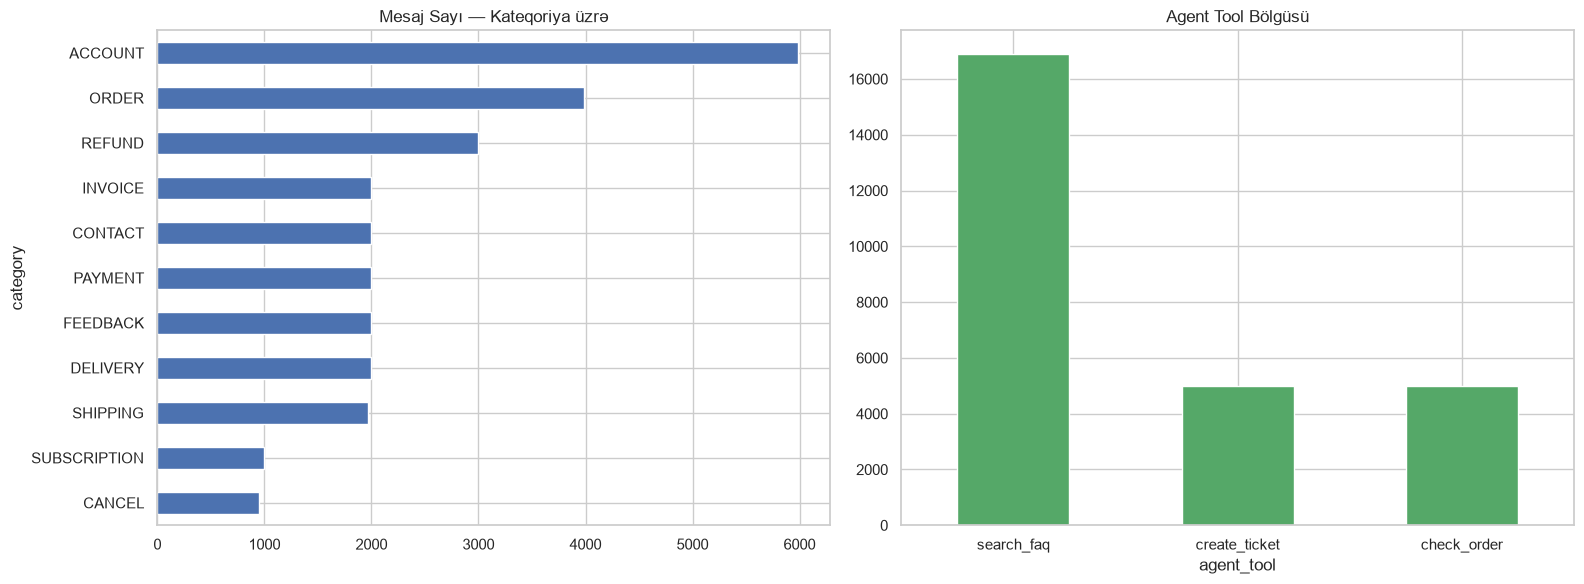

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
bt["category"].value_counts().plot(kind="barh", ax=axes[0], color=sns.color_palette("deep")[0])
axes[0].set_title("Mesaj Sayı — Kateqoriya üzrə")
axes[0].invert_yaxis()

bt["agent_tool"].value_counts().plot(kind="bar", ax=axes[1], color=sns.color_palette("deep")[2])
axes[1].set_title("Agent Tool Bölgüsü")
axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()


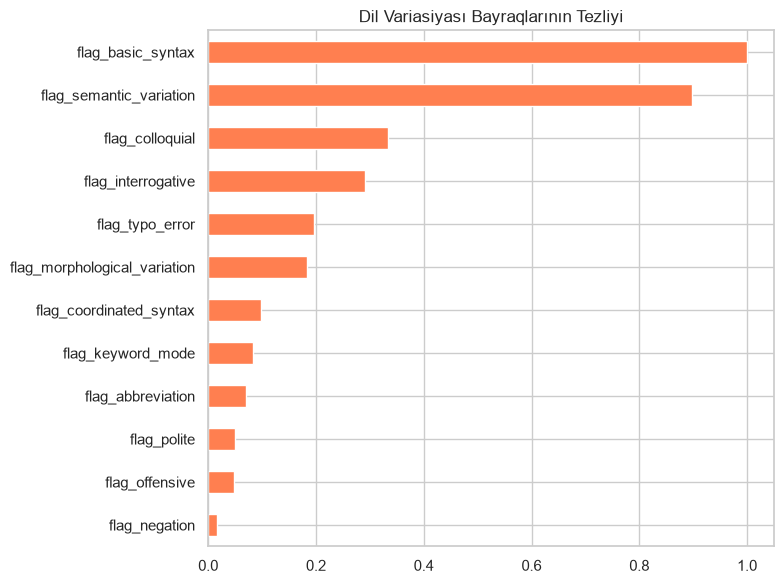

In [18]:
flag_means = bt[[f"flag_{n}" for n in FLAG_MAP.values()]].mean().sort_values()
plt.figure(figsize=(8, 6))
flag_means.plot(kind="barh", color="coral")
plt.title("Dil Variasiyası Bayraqlarının Tezliyi")
plt.tight_layout()
plt.show()


## 8. Model A — İntent Təsnifatı (27-sinif)

In [19]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

X_text = bt["instruction_clean"].astype(str)
y_intent = bt["intent"].astype(str)
Xtr, Xte, ytr, yte = train_test_split(X_text, y_intent, test_size=0.2, random_state=RANDOM_STATE, stratify=y_intent)

tfidf = TfidfVectorizer(max_features=6000, ngram_range=(1, 2), min_df=2)
Xtr_vec = tfidf.fit_transform(Xtr)
Xte_vec = tfidf.transform(Xte)

clf_intent = LogisticRegression(max_iter=300, C=5.0)
clf_intent.fit(Xtr_vec, ytr)
pred_intent = clf_intent.predict(Xte_vec)

print(f"Accuracy : {accuracy_score(yte, pred_intent):.4f}")
print(f"Macro-F1 : {f1_score(yte, pred_intent, average='macro'):.4f}")
print(f"Baseline (təsadüfi, {y_intent.nunique()} sinif): {1/y_intent.nunique():.4f}")


Accuracy : 0.9950
Macro-F1 : 0.9950
Baseline (təsadüfi, 27 sinif): 0.0370


## 9. Model B — Kateqoriya Təsnifatı (11-sinif)

In [20]:
y_cat = bt["category"].astype(str)
Xtr, Xte, ytr, yte = train_test_split(X_text, y_cat, test_size=0.2, random_state=RANDOM_STATE, stratify=y_cat)
Xtr_vec = tfidf.transform(Xtr)
Xte_vec = tfidf.transform(Xte)

clf_cat = LogisticRegression(max_iter=300, C=5.0)
clf_cat.fit(Xtr_vec, ytr)
pred_cat = clf_cat.predict(Xte_vec)

print(f"Accuracy : {accuracy_score(yte, pred_cat):.4f}")
print(f"Macro-F1 : {f1_score(yte, pred_cat, average='macro'):.4f}")


Accuracy : 0.9978
Macro-F1 : 0.9978


## 10. Model C — Agent Tool-Routing Modeli

In [21]:
from sklearn.naive_bayes import MultinomialNB

y_tool = bt["agent_tool"].astype(str)
Xtr, Xte, ytr, yte = train_test_split(X_text, y_tool, test_size=0.2, random_state=RANDOM_STATE, stratify=y_tool)
Xtr_vec = tfidf.transform(Xtr)
Xte_vec = tfidf.transform(Xte)

clf_tool = LogisticRegression(max_iter=300, C=5.0, class_weight="balanced")
clf_tool.fit(Xtr_vec, ytr)
pred_tool = clf_tool.predict(Xte_vec)

clf_nb = MultinomialNB()
clf_nb.fit(Xtr_vec, ytr)
pred_nb = clf_nb.predict(Xte_vec)

print(f"Logistic Regression Accuracy : {accuracy_score(yte, pred_tool):.4f}")
print(f"Naive Bayes Accuracy         : {accuracy_score(yte, pred_nb):.4f}")
print(f"Baseline (təsadüfi, 3 sinif) : {1/3:.4f}")
print()
print(classification_report(yte, pred_tool))


Logistic Regression Accuracy : 0.9963
Naive Bayes Accuracy         : 0.9873
Baseline (təsadüfi, 3 sinif) : 0.3333

               precision    recall  f1-score   support

  check_order       1.00      1.00      1.00       997
create_ticket       0.99      0.99      0.99       999
   search_faq       1.00      1.00      1.00      3379

     accuracy                           1.00      5375
    macro avg       1.00      1.00      1.00      5375
 weighted avg       1.00      1.00      1.00      5375



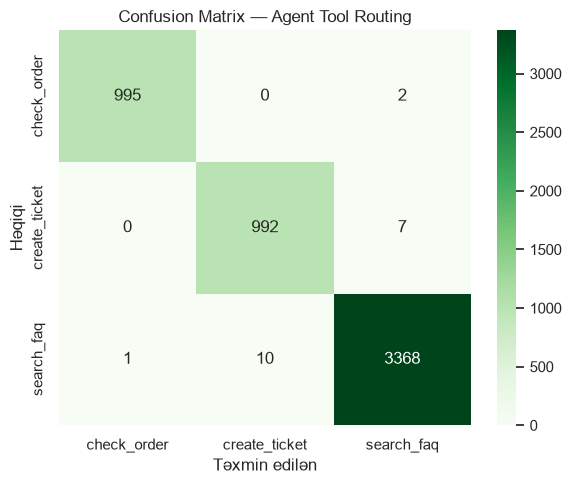

In [22]:
labels_tool = sorted(y_tool.unique())
cm = confusion_matrix(yte, pred_tool, labels=labels_tool)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=labels_tool, yticklabels=labels_tool)
plt.title("Confusion Matrix — Agent Tool Routing")
plt.xlabel("Təxmin edilən")
plt.ylabel("Həqiqi")
plt.tight_layout()
plt.show()


---
# HİSSƏ 3 — İnteqrasiya

## 11. Modellərin Saxlanması


In [23]:
MODELS_DIR = "models"
os.makedirs(MODELS_DIR, exist_ok=True)

# Olist modelləri
joblib.dump(clf_late, f"{MODELS_DIR}/olist_late_delivery_classifier.pkl")
joblib.dump(late_encoders, f"{MODELS_DIR}/olist_late_encoders.pkl")
joblib.dump(pre_delivery_features, f"{MODELS_DIR}/olist_late_feature_order.pkl")
joblib.dump(clf_rev, f"{MODELS_DIR}/olist_bad_review_classifier.pkl")
joblib.dump(rev_encoders, f"{MODELS_DIR}/olist_review_encoders.pkl")
joblib.dump(post_delivery_features, f"{MODELS_DIR}/olist_review_feature_order.pkl")

# Bitext modelləri
joblib.dump(tfidf, f"{MODELS_DIR}/tfidf_vectorizer.pkl")
joblib.dump(clf_intent, f"{MODELS_DIR}/intent_classifier.pkl")
joblib.dump(clf_cat, f"{MODELS_DIR}/category_classifier.pkl")
joblib.dump(clf_tool, f"{MODELS_DIR}/tool_router_classifier.pkl")

print("Bütün 6 model faylı 'models/' qovluğuna saxlanıldı:")
print(os.listdir(MODELS_DIR))


Bütün 6 model faylı 'models/' qovluğuna saxlanıldı:
['category_classifier.pkl', 'intent_classifier.pkl', 'olist_bad_review_classifier.pkl', 'olist_late_delivery_classifier.pkl', 'olist_late_encoders.pkl', 'olist_late_feature_order.pkl', 'olist_review_encoders.pkl', 'olist_review_feature_order.pkl', 'tfidf_vectorizer.pkl', 'tool_router_classifier.pkl']


> **Colab-dan yükləmək üçün:**
> ```python
> import shutil
> from google.colab import files
> shutil.make_archive("project_artifacts", "zip", ".", "models")
> files.download("project_artifacts.zip")
> ```


## 12. Vahid Agent Simulyasiyası

Real LLM Agent-in işləmə axını: istifadəçi mesajı → Model C mesajı bir
alətə marşrutlaşdırır → əgər `check_order` seçilibsə, Olist modelləri
(D/E) o sifariş üçün risk qiymətləndirməsi verir.


In [24]:
def simulate_full_agent(message: str, order_context: dict = None):
    vec = tfidf.transform([message])
    intent = clf_intent.predict(vec)[0]
    tool = clf_tool.predict(vec)[0]
    tool_conf = clf_tool.predict_proba(vec).max()

    print(f"👤 İstifadəçi: {message}")
    print(f"🎯 İntent: {intent}  |  🔧 Alət: {tool}  (etibar: {tool_conf:.1%})")

    if tool == "check_order" and order_context is not None:
        row = pd.DataFrame([order_context])[pre_delivery_features].copy()
        for c in pre_delivery_cat:
            row[c] = late_encoders[c].transform(row[[c]])
        late_risk = clf_late.predict_proba(row)[0][1]
        print(f"   → check_order() çağırılır → Gecikmə riski: {late_risk:.1%}")
        if late_risk > 0.3:
            print("   ⚠️  Yüksək risk — müştəriyə proaktiv bildiriş tövsiyə olunur")
    elif tool == "create_ticket":
        print(f'   → create_ticket(category="{intent}", priority="normal") çağırılır')
    else:
        print(f'   → search_faq(topic="{intent}") çağırılır')
    print()


# Nümunə sifariş konteksti (Olist feature formatında)
sample_order = {
    "n_items": 1, "total_price": 150.0, "total_freight": 25.0, "avg_price": 150.0,
    "payment_installments": 3, "approval_delay_hours": 5.0, "cross_state": 1,
    "purchase_month": 11, "purchase_dow": 4,
    "customer_state": "SP", "seller_state": "RJ",
    "product_category_name_english": "electronics", "payment_type": "credit_card",
}

simulate_full_agent("where is my order, it hasn't arrived yet", order_context=sample_order)
simulate_full_agent("I was charged twice, I want to file a complaint")
simulate_full_agent("what is your refund policy")


👤 İstifadəçi: where is my order, it hasn't arrived yet
🎯 İntent: delivery_period  |  🔧 Alət: search_faq  (etibar: 71.9%)
   → search_faq(topic="delivery_period") çağırılır

👤 İstifadəçi: I was charged twice, I want to file a complaint
🎯 İntent: complaint  |  🔧 Alət: create_ticket  (etibar: 99.5%)
   → create_ticket(category="complaint", priority="normal") çağırılır

👤 İstifadəçi: what is your refund policy
🎯 İntent: check_refund_policy  |  🔧 Alət: search_faq  (etibar: 98.5%)
   → search_faq(topic="check_refund_policy") çağırılır



## 13. Nəticə və Biznes Tövsiyələri

### Xülasə

| Model | Dataset | Metrik | Nəticə | Baseline |
|---|---|---|---|---|
| A. İntent (27 sinif) | Bitext | Accuracy | 99.5% | 3.7% |
| B. Kateqoriya (11 sinif) | Bitext | Accuracy | 99.8% | 9.1% |
| C. Tool-Routing (3 sinif) | Bitext | Accuracy | 99.6% | 33.3% |
| D. Gecikmə Riski | Olist | ROC-AUC | 0.75 | 0.50 |
| E. Narazılıq Riski | Olist | ROC-AUC | 0.76 | 0.50 |

### Metodoloji nəticələr
- **Bitext modelləri** (mətn əsaslı) demək olar mükəmməl dəqiqliklə işləyir —
  "təmiz" NLP ssenarisi (aydın etiketlənmiş, linqvistik cəhətdən ayırd edilə
  bilən dataset)
- **Olist modelləri** (real dünya, balanssız data) daha real bir mənzərə
  göstərir: mütləq accuracy aldadıcı ola bilər, ROC-AUC/F1 həqiqi
  proqnozlaşdırma gücünü göstərir. Hər iki model təsadüfi baseline-ı
  (0.50 AUC) əhəmiyyətli dərəcədə üstələyir — real, işlək siqnal var

### LLM Agent inteqrasiyası
- `search_faq` / `create_ticket` → Bitext modelləri ilə istifadəçi mesajını
  şərh edir
- `check_order` → çağırılanda Olist modelləri arxa planda gecikmə/narazılıq
  riskini qiymətləndirir və agent-ə proaktiv fəaliyyət tövsiyə edir (məsələn,
  "bu sifariş gecikə bilər, müştəriyə əvvəlcədən bildiriş göndər")

### Növbəti addımlar
1. İki modeli vahid API arxasında birləşdirmək (FastAPI/Flask servisi)
2. Real sifariş sistemi ilə inteqrasiya edərək canlı gecikmə riski
   monitorinqi qurmaq
3. Bitext modelini real müştəri mesajları ilə fine-tune etmək
4. A/B test ilə proaktiv bildirişlərin müştəri məmnuniyyətinə təsirini ölçmək
